## Q1. Image Processing Pipeline Implementation
Take any real-world color image and perform the following operations using Python/OpenCV:

1.​ Read and display the image.
2.​ Convert it into Grayscale, RGB and HSV representations.
3.​ Resize the image and explain the effect of sampling.
4.​ Apply mean, median and Gaussian filtering and compare the results.
5.​ Perform basic brightness and contrast adjustment.
6.​ Apply histogram equalization on the grayscale image.
7.​ Display the original and processed images and briefly explain the effect of each operation.

Expected output: Source code in form of ipynb file + original/processed images + a short
observation for each operation.

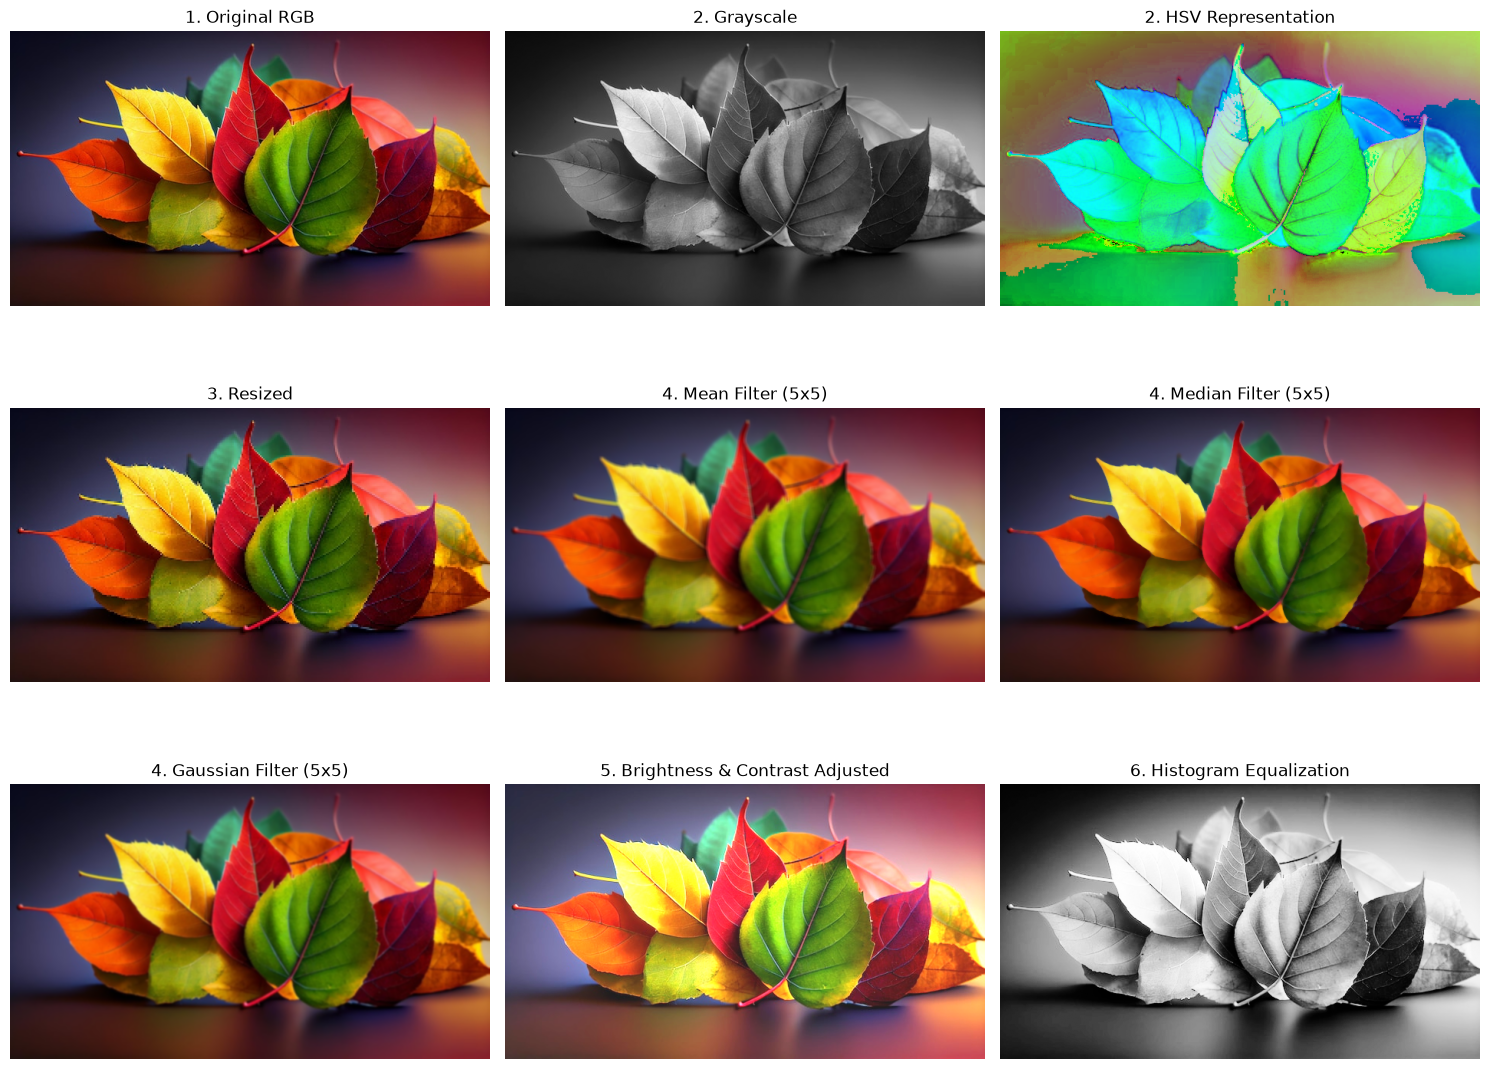

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# 1. Read the image
img_bgr = cv2.imread('image.jpg')


# 2. Convert into RGB, Grayscale, and HSV representations
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# 3. Resize the image (Sampling) Downsampling to 50% of the original size
width, height = img_rgb.shape[1], img_rgb.shape[0]
img_downsampled = cv2.resize(img_rgb, (width // 2, height // 2), interpolation=cv2.INTER_NEAREST)

# 4. Apply Filtering
# Mean Filter (Averaging)
img_mean = cv2.blur(img_rgb, (5, 5))
# Median Filter (Non-linear)
img_median = cv2.medianBlur(img_rgb, 5)
# Gaussian Filter (Weighted Average)
img_gaussian = cv2.GaussianBlur(img_rgb, (5, 5), 0)

# 5. Basic Brightness and Contrast Adjustment
alpha = 1.3  
beta = 30    
img_bright_contrast = cv2.convertScaleAbs(img_rgb, alpha=alpha, beta=beta)

# 6. Apply Histogram Equalization on the Grayscale image
img_hist_eq = cv2.equalizeHist(img_gray)

# 7. Display the original and processed images manually
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
ax = axes.ravel()

# Plot 1: Original RGB
ax[0].imshow(img_rgb)
ax[0].set_title("1. Original RGB")
ax[0].axis('off')

# Plot 2: Grayscale
ax[1].imshow(img_gray, cmap='gray')
ax[1].set_title("2. Grayscale")
ax[1].axis('off')

# Plot 3: HSV Representation
ax[2].imshow(img_hsv)
ax[2].set_title("2. HSV Representation")
ax[2].axis('off')

# Plot 4: Resized 
ax[3].imshow(img_downsampled)
ax[3].set_title("3. Resized")
ax[3].axis('off')

# Plot 5: Mean Filter
ax[4].imshow(img_mean)
ax[4].set_title("4. Mean Filter (5x5)")
ax[4].axis('off')

# Plot 6: Median Filter
ax[5].imshow(img_median)
ax[5].set_title("4. Median Filter (5x5)")
ax[5].axis('off')

# Plot 7: Gaussian Filter
ax[6].imshow(img_gaussian)
ax[6].set_title("4. Gaussian Filter (5x5)")
ax[6].axis('off')

# Plot 8: Brightness & Contrast Adjusted
ax[7].imshow(img_bright_contrast)
ax[7].set_title("5. Brightness & Contrast Adjusted")
ax[7].axis('off')

# Plot 9: Histogram Equalization 
ax[8].imshow(img_hist_eq, cmap='gray')
ax[8].set_title("6. Histogram Equalization")
ax[8].axis('off')

plt.tight_layout()
plt.show()




**1. Reading and Color Correction (BGR to RGB)**

* **Effect:** By default, OpenCV reads digital images in a Blue-Green-Red (BGR) channel format, which is an inverted color space compared to standard display rendering. Converting the image to RGB rearranges the channels, ensuring that colors are displayed naturally and correctly when visualized using plotting libraries.

**2. Color Space Conversions (Grayscale and HSV)**

* **Grayscale Conversion:** This operation collapses the 3-channel (color) image into a single-channel image representing only pixel intensity (brightness). It entirely removes hue and saturation data. This reduces computational complexity for structural tasks like edge detection where color information is unnecessary.
* **HSV (Hue, Saturation, Value) Conversion:** This transformation separates the color information (Hue) from the color purity (Saturation) and lighting intensity (Value). Unlike RGB, where shadows alter all three channels, HSV isolates illumination changes into the 'Value' channel alone, making it highly effective for object tracking under varying lighting conditions.

**3. Image Resizing (The Effect of Sampling)**

* **Effect of Sampling:** Sampling alters the spatial resolution of the image grid. When an image is resized smaller (downsampled), pixels are discarded. This reduces the overall file size and processing time but permanently destroys fine image details. If performed without proper pre-filtering, downsampling introduces **aliasing**, where smooth curves and sharp edges appear jagged or pixelated.

**4. Spatial Filtering (Mean, Median, and Gaussian)**

* **Mean Filter:** Computes a simple mathematical average of all pixels within the kernel.
* *Observation:* It applies a heavy, uniform blur across the entire image. It is highly destructive to sharp edges and fine structural details.


* **Median Filter:** Replaces the central pixel with the median value of its neighboring pixels.
* *Observation:* It introduces almost no artificial blur and exceptionally preserves sharp edges. It is highly effective at eliminating impulse noise (salt-and-pepper noise) because extreme pixel values are ignored during the sorting process.


* **Gaussian Filter:** Computes a weighted average, prioritizing pixels closer to the center of the kernel based on a bell curve distribution.
* *Observation:* It produces a much smoother, more natural-looking blur than the mean filter. It effectively removes Gaussian noise (like low-light camera grain) while being less destructive to object boundaries.



**5. Brightness and Contrast Adjustment**

* **Effect:** This is a linear pixel transformation based on the formula $g(x,y) = \alpha \cdot f(x,y) + \beta$.
* Multiplying by a scaling factor ($\alpha$) adjusts the **contrast**, stretching or compressing the difference between the darkest and lightest pixels.
* Adding a constant bias ($\beta$) shifts the **brightness**, uniformly increasing or decreasing the overall intensity of the entire image.



**6. Histogram Equalization**

* **Effect:** This operation analyzes the frequency of every intensity value in the grayscale image and redistributes them to create a flat, uniform histogram. By stretching the most frequent pixel intensities across the full 0–255 range, it significantly enhances the global contrast.
* *Observation:* Details that were previously hidden in heavily shadowed (dark) or overexposed (bright) regions become highly visible and distinct.